# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [147]:
STUDENT_NAME = 'Потапова Світлана'     
LIST_NUMBER  = 16   

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 16: Черкаси, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [148]:
CITY = 'Львів, Україна'

In [149]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [150]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [151]:
import osmnx as ox

OUT = 'lviv_osm'
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: lviv_osm


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [152]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [153]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    t0, b0 = time.time(), cache_bytes()
    g = clean(getter())
    g.to_parquet(path, index=False)
    g = gpd.read_parquet(path)
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 1)}
    return g

In [154]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 148.4 км²


In [155]:
b = gpd.read_parquet(os.path.join(OUT, 'buildings.parquet'))
print('будівель:', len(b))
for c in ['historic', 'tourism', 'wikidata', 'wikipedia', 'name', 'building', 'railway']:
    print('%-10s %s' % (c, int(b[c].notna().sum()) if c in b.columns else 'колонки немає'))
print('name:* колонок:', len([c for c in b.columns if c.startswith('name:')]))

n = gpd.read_parquet(os.path.join(OUT, 'road_nodes.parquet'))
e = gpd.read_parquet(os.path.join(OUT, 'road_edges.parquet'))
print('nodes:', list(n.columns))
print('edges:', list(e.columns))

будівель: 46214
historic   78
tourism    75
wikidata   182
wikipedia  146
name       1925
building   46214
railway    2
name:* колонок: 20
nodes: ['osmid', 'y', 'x', 'street_count', 'highway', 'railway', 'ref', 'junction', 'geometry']
edges: ['u', 'v', 'key', 'osmid', 'highway', 'lanes', 'name', 'oneway', 'reversed', 'length', 'geometry', 'maxspeed', 'ref', 'bridge', 'width', 'access', 'junction', 'tunnel']


In [156]:
def pick(df, cols_vals):
    m = pd.Series(False, index=df.index)
    for col, vals in cols_vals.items():
        if col in df.columns:
            m |= df[col].notna() if vals is True else df[col].isin(vals)
    return df[m]

h = pick(b, {'historic': True, 'tourism': TOURISM_OK})
s = pick(b, {'railway': ['station', 'halt'], 'building': ['train_station']})
print('heritage:', len(h), '| stations:', len(s))

h.to_parquet(os.path.join(OUT, 'heritage.parquet'), index=False)
s.to_parquet(os.path.join(OUT, 'stations.parquet'), index=False)

heritage: 109 | stations: 7


In [157]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 3668 | ребер 8627


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [158]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.028,0.047
heritage,знімок,109,0.0,0.244,0.156
stations,знімок,7,0.0,0.202,0.137
amenities,знімок,1526,0.0,0.324,0.086
мережа walk,знімок,12295,0.0,1.097,0.088


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

### Висновок до завдання 1.2

Порівняння «живий запит проти знімка» виконати не вдалося.
Живий запит до Overpass API не пройшов (сервери відповідали HTTP 502, HTTP 403 або таймаутом). Нормально відпрацювало лише завантаження межі міста,
бо воно йде через Nominatim, а не через Overpass. 

Тому всі шари прочитано зі знімка (теку Lviv_osm), і в таблиці COST
кожен рядок має спосіб «знімок». 

Що саме виміряно для знімка:
- передано мережею: 0 МБ (усі 5 шарів);
- прочитано з диска: 1,9 МБ файлів;
- час читання всіх шарів: приблизно 0,5 с.


(у знімку Lviv_osm шарів heritage та stations не було. Я виділила їх із шару buildings за тегами historic, tourism, railway, building=train_station. Тому пам'ятки які в OSM є окремими точками (пам'ятники, меморіали), в основному
відсутні)

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [159]:
by_tags = heritage['historic'].notna() | heritage['tourism'].isin(TOURISM_OK)
has_name = heritage['name'].notna() & (heritage['name'].str.strip() != '')

cand = heritage[by_tags & has_name].reset_index(drop=True)
print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(by_tags.sum()))
print('з них мають name       :', len(cand))

no_tags = ~by_tags
no_name = by_tags & ~has_name
print()
print('відкинуто за тегами    :', int(no_tags.sum()))
print('відкинуто без назви    :', int(no_name.sum()))
print('разом відкинуто        :', int((~(by_tags & has_name)).sum()))

print('\nвідкинуті без назви, за типом:')
print(heritage[no_name]['historic'].fillna(heritage[no_name]['tourism'])
      .value_counts().head(10).to_string())


усього у шарі heritage : 109
підходять за тегами    : 109
з них мають name       : 95

відкинуто за тегами    : 0
відкинуто без назви    : 14
разом відкинуто        : 14

відкинуті без назви, за типом:
historic
heritage       4
museum         4
building       2
yes            2
gallery        1
railway_car    1


In [160]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
house       18
yes         18
church       6
building     4
tomb         4
ruins        3
tower        2
monument     2
castle       2
memorial     2

=== tourism ===
tourism
museum        22
attraction     8
artwork        1

типи геометрії: {'Polygon': 95}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

### Висновок до завдання 2.1

Відбір: У шарі heritage було 109 об'єктів. Я взяла об'єднання двох
умов: заповнений historic АБО tourism зі списку (museum, attraction,
gallery, artwork, viewpoint), і лишила лише ті, що мають назву.

- за тегами підійшли всі 109, тому відсіву за тегами 0 (шар уже було
  виділено з buildings за цими самими тегами);
- відкинуто 14 об'єктів без name. Серед них
  4 музеї, 1 галерея, 4 з historic=heritage, 2 building, 2 yes,
  1 railway_car. Без назви об'єкт не можна показати туристу, не можна
  зіставити з вікі та порахувати мови назви;
- лишилось 95 кандидатів.

Склад кандидатів: historic лідирують house (18) та yes (18),
далі church (6), building (4), tomb (4), ruins (3); у tourism
22 музеї, 8 атракцій, 1 арт-об'єкт.

Усі 95 об'єктів мають геометрію Polygon, точок немає. Причина: heritage я виділила з шару buildings, а пам'ятники, меморіали та оглядові точки в OSM є вузлами й у buildings не потрапляють

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [161]:
import re

metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

def filled(s):
    return s.notna() & (s.astype(str).str.strip() != '')

cand['wiki'] = (filled(cand['wikidata']) | filled(cand['wikipedia'])).astype(int)

lang_cols = [c for c in cand.columns if re.fullmatch(r'name:[a-z]{2,3}', c)]
print('колонки мов:', lang_cols)
cand['n_lang'] = cand[lang_cols].notna().sum(axis=1)

GENERIC = ['yes', 'house', 'building', 'heritage']
cand['kind'] = (cand['tourism'].isin(['museum', 'gallery', 'attraction'])
                | (cand['historic'].notna() & ~cand['historic'].isin(GENERIC))).astype(int)

cand['r_lang'] = cand['n_lang'].rank(pct=True, method='min')
cand['r_area'] = cand['area_m2'].rank(pct=True, method='min')

W = {'wiki': 0.35, 'lang': 0.30, 'kind': 0.20, 'area': 0.15}
cand['score'] = (W['wiki'] * cand['wiki'] + W['lang'] * cand['r_lang']
                 + W['kind'] * cand['kind'] + W['area'] * cand['r_area'])

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('мають мови   :', int((cand['n_lang'] > 0).sum()))
print('конкретний тип:', int(cand['kind'].sum()))
display(cand.nlargest(15, 'score')[['name', 'historic', 'tourism', 'wiki', 'n_lang', 'kind', 'area_m2', 'score']])

колонки мов: ['name:uk', 'name:en', 'name:be', 'name:cs', 'name:fr', 'name:lt', 'name:pl', 'name:ru', 'name:he', 'name:de', 'name:it', 'name:ja', 'name:tr', 'name:es', 'name:hu', 'name:zh', 'name:pt']
кандидатів   : 95
мають wiki   : 29
мають мови   : 92
конкретний тип: 53


,name,historic,tourism,wiki,n_lang,kind,area_m2,score
0,Національний музей у Львові,<NA>,museum,1,6,1,2003.835416,0.984211
28,Палац Потоцьких,castle,museum,1,6,1,1351.056547,0.981053
15,Королівський арсенал,<NA>,museum,1,6,1,1132.640612,0.976316
1,Львівський музей історії релігії,<NA>,museum,1,5,1,2310.243274,0.970000
2,Львівський Державний Природознавчий Музей,<NA>,museum,1,5,1,1177.017979,0.963684
8,Кам'яниця Корнякта,<NA>,museum,1,6,1,579.401407,0.960526
10,"Арсенал, Львівський державний історичний музей...",<NA>,museum,1,5,1,993.524045,0.954211
22,Будинок вчених,monument,<NA>,1,4,1,1446.755204,0.947895
23,Львівська національна галерея мистецтв,<NA>,museum,1,4,1,1157.389270,0.943158
14,Порохова Вежа,<NA>,attraction,1,5,1,460.529773,0.941579


### Критерій рейтингу (завдання 3.1)

У даних немає поля «цінність», тому я побудувала її з чотирьох сигналів
OSM, кожен переведено на шкалу 0..1:

| сигнал | як рахується | вага | чому така |
|---|---|---|---|
| wiki | є wikidata або wikipedia (0 чи 1) | 0,35 | Найсильніший: стаття означає, що хтось сторонній визнав об'єкт вартим опису. Накрутити випадково важко. |
| n_lang | кількість колонок name:xx (лише коди мов), через rank(pct=True) | 0,30 | Назву перекладають тим, що шукають іноземці. Ранг, а не сире число, бо 6 мов не удвічі краще за 3. |
| kind | музей, галерея, атракція або конкретний тип historic (не yes, house, building, heritage) | 0,20 | Показує призначення для відвідування. Вага менша, бо тип у OSM ставлять неохайно. |
| area_m2 | площа полігона, через rank(pct=True) | 0,15 | Найслабший сигнал: великою буває і будівля складу. Лише розрізняє об'єкти, рівні за іншим. |

score = 0,35\*wiki + 0,30\*r_lang + 0,20\*kind + 0,15\*r_area

Порядок ваг відповідає надійності сигналу: спершу зовнішнє визнання
(wiki, мови), потім призначення (kind), останньою розмір.

Перевірка на чутливість: Я змінила ваги на wiki 0,25 і area 0,25.
Склад верхніх 15 об'єктів не змінився, лише дрібно перемішався порядок
(наприклад, Кам'яниця Корнякта з 6-го місця опустилась на 8-е). Отже,
критерій стійкий до вибору ваг у розумних межах.

### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [162]:
N_SMALL, N_LARGE = 10, 30

cand['cid'] = range(len(cand))

top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)

common  = set(top10['cid']) & set(top_naive['cid'])
overlap = len(common)
print('перетин: %d з %d' % (overlap, N_SMALL))
print('спільні :', list(cand[cand['cid'].isin(common)]['name']))

display(pd.DataFrame({
    'за вашим критерієм': list(top10['name']),
    'за площею':          list(top_naive['name']),
    'площа, м² (площа-топ)': [round(a) for a in top_naive['area_m2']],
    'wiki (площа-топ)':      list(top_naive['wiki']),
    'n_lang (площа-топ)':    list(top_naive['n_lang']),
}))

перетин: 7 з 10
спільні : ['Національний музей у Львові', 'Львівський музей історії релігії', 'Львівський Державний Природознавчий Музей', 'Королівський арсенал', 'Будинок вчених', 'Львівська національна галерея мистецтв', 'Палац Потоцьких']


,за вашим критерієм,за площею,"площа, м² (площа-топ)",wiki (площа-топ),n_lang (площа-топ)
0,Національний музей у Львові,Австрійський форт,2358,0,1
1,Палац Потоцьких,Львівський музей історії релігії,2310,1,5
2,Королівський арсенал,Національний музей у Львові,2004,1,6
3,Львівський музей історії релігії,Будинок вчених,1447,1,4
4,Львівський Державний Природознавчий Музей,Палац Потоцьких,1351,1,6
5,Кам'яниця Корнякта,Львівський Державний Природознавчий Музей,1177,1,5
6,"Арсенал, Львівський державний історичний музей...",Львівська національна галерея мистецтв,1157,1,4
7,Будинок вчених,Королівський арсенал,1133,1,6
8,Львівська національна галерея мистецтв,Велика Максиміліанська вежа №1,1128,0,2
9,Порохова Вежа,Палац Любомирських,1061,1,4


### Висновок до завдання 3.2

Я порівняла топ-10 за власним критерієм і топ-10 за найпростішою
ознакою, площею будівлі. Збіглося 7 з 10 об'єктів: Національний музей
у Львові, Львівський музей історії релігії, Львівський Державний
Природознавчий Музей, Королівський арсенал, Будинок вчених, Львівська
національна галерея мистецтв, Палац Потоцьких.

Збігів багато, бо серед кандидатів великі будівлі здебільшого і є відомими: музеї та палаци займають великі площі, а ці самі об'єкти мають вікі-статті й назви кількома мовами. 

Де списки розійшлись (3 об'єкти з 10). У топі за площею, але не в
моєму:
- Австрійський форт, 2358 м², найбільший об'єкт, але без вікі і лише з однією мовою назви;
- Велика Максиміліанська вежа №1, 1128 м², теж без вікі й із двома
  мовами;
- Палац Любомирських, 1061 м², має вікі й 4 мови, тож у мій топ-10
  він не потрапив лише тому, що в нього 11-те місце за рейтингом.

У моєму топі, але не в топі за площею: Кам'яниця Корнякта (579 м²), Арсенал (Львівський державний історичний музей, 993 м²) і Порохова вежа (461 м²). Це менші за розміром, але добре задокументовані об'єкти.

Що це означає для слова «найкращі»: «Найкращі» не є властивістю даних, це результат вибору критерію. Площа вимірює розмір, мій рейтинг вимірює міру зовнішнього визнання. Найбільший об'єкт (Австрійський форт) без жодної вікі-статті, і для туриста він навряд чи головний. Водночас висока збіжність (70%) показує, що для цього міста критерії не суперечать один одному
радикально.

### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [163]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

pairs = close_pairs(top_score, limit_m=60)
print('пар ближче 60 м у top_score (30 об\'єктів):', len(pairs))

rows = []
for i, j, d in pairs:
    a, b = top_score.iloc[i], top_score.iloc[j]
    rows.append({
        'об\'єкт A': a['name'], 'об\'єкт B': b['name'],
        'відстань, м': round(d, 1),
        'score A': round(a['score'], 3), 'score B': round(b['score'], 3),
        'wiki A/B': '%d/%d' % (a['wiki'], b['wiki']),
        'мови A/B': '%d/%d' % (a['n_lang'], b['n_lang']),
        'тип A': a['tourism'] if pd.notna(a['tourism']) else a['historic'],
        'тип B': b['tourism'] if pd.notna(b['tourism']) else b['historic'],
        'ранг A/B': '%d/%d' % (i + 1, j + 1),
    })
pairs_df = pd.DataFrame(rows)
display(pairs_df)

p10 = [p for p in pairs if p[0] < 10 and p[1] < 10]
print('з них обидва в топ-10:', len(p10))

for i, j, d in pairs:
    wa, wb = top_score.loc[i, 'wikidata'], top_score.loc[j, 'wikidata']
    print(top_score.loc[i, 'name'], '|', top_score.loc[j, 'name'], '|', wa, wb, '| однакове:', wa == wb)

пар ближче 60 м у top_score (30 об'єктів): 6


,об'єкт A,об'єкт B,"відстань, м",score A,score B,wiki A/B,мови A/B,тип A,тип B,ранг A/B
0,Львівський музей історії релігії,Музей Історії та Релігії,26.2,0.970,0.604,1/0,5/6,museum,museum,4/24
1,"Арсенал, Львівський державний історичний музей...",Рештки вежі токарів,29.0,0.954,0.605,1/1,5/1,museum,attraction,7/23
2,Королівський арсенал,Музей Історії та Релігії,53.7,0.976,0.604,1/0,6/6,museum,museum,3/24
3,Музей Михайла Грушевського,Музей Івана Франка,55.8,0.728,0.706,1/1,2/2,museum,museum,17/18
4,Палац Потоцьких,Музей мистецтва давньої української книги,58.8,0.981,0.908,1/1,6/3,museum,museum,2/14
5,"Каплиця, с. Ялинкувате, 60-70х рр. ХІХ ст.","Церква Премудрості Божої, с. Кривка, 1763",59.1,0.667,0.532,1/0,2/3,chapel,church,20/29


з них обидва в топ-10: 0
Львівський музей історії релігії | Музей Історії та Релігії | Q4306348 <NA> | однакове: <NA>
Арсенал, Львівський державний історичний музей старовинної зброї | Рештки вежі токарів | Q1967013 Q12134978 | однакове: False
Королівський арсенал | Музей Історії та Релігії | Q4233747 <NA> | однакове: <NA>
Музей Михайла Грушевського | Музей Івана Франка | Q12100446 Q12119146 | однакове: False
Палац Потоцьких | Музей мистецтва давньої української книги | Q1576016 Q4306287 | однакове: False
Каплиця, с. Ялинкувате, 60-70х рр. ХІХ ст. | Церква Премудрості Божої, с. Кривка, 1763 | Q122278715 <NA> | однакове: <NA>


In [164]:
DROP_NAMES = ['Музей Історії та Релігії',
              'Рештки вежі токарів']
drop_mask = cand['name'].apply(lambda s: any(s.startswith(n) for n in DROP_NAMES))
print('видаляємо:', list(cand[drop_mask]['name']))

pool = cand[~drop_mask]
top_score = pool.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10 = top_score.head(N_SMALL)

видаляємо: ['Музей Історії та Релігії', 'Рештки вежі токарів']


### Висновок до завдання 3.3 (дублікати)

У топ-30 знайдено 6 пар ближче 60 м, жодна не торкається топ-10.
Рішення:

- Злито (1): «Львівський музей історії релігії» і «Музей Історії та
  Релігії» (26 м): один музей під двома назвами. Лишила запис із
  вікі-статтею (score 0,970 проти 0,604). Через це зникла й пара
  «Королівський арсенал» + «Музей Історії та Релігії» (54 м).
- Видалено як частину іншого об'єкта (1): «Рештки вежі токарів»
  (прилягає до Арсеналу).
- Лишено (3 пари): музеї Грушевського і Франка (56 м), Палац
  Потоцьких і Музей давньої української книги (59 м), каплиця
  с. Ялинкувате і церква с. Кривка (59 м). Це різні об'єкти з різним
  віком і призначенням (скансен: споруди перенесено з різних сіл, але
  стоять вони поруч, в одному гаю), тому кожна окремо є культурною
  пам'яткою.

---
## 4. Старт: вокзал, і прив'язка точок до графа

In [165]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 7
                name  railway       building
0              Сихів     <NA>  train_station
1  Приміський вокзал     <NA>  train_station
2    Головний вокзал     <NA>  train_station
3       ст. Підзамче     <NA>  train_station
4               <NA>     <NA>  train_station
5               <NA>  station            yes
6              Рясна     halt            yes


In [166]:
station = stations[stations['name'] == 'Головний вокзал'].head(1).reset_index(drop=True)
print('старт:', station['name'].iloc[0])
print('тип геометрії:', station.geometry.iloc[0].geom_type)

старт: Головний вокзал
тип геометрії: Polygon


In [167]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 3668 вузлів, 8554 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [168]:
def check_snap(points, ids, dist, label):
    n_pts = len(ids)
    n_uniq = len(set(ids))
    print('=== %s ===' % label)
    print('точок            : %d' % n_pts)
    print('різних вузлів    : %d' % n_uniq)
    print('відстань точка->вузол: медіана %.0f м, максимум %.0f м'
          % (np.median(dist), np.max(dist)))

    k = int(np.argmax(dist))
    print('найдальша        : %s (%.0f м)' % (points['name'].iloc[k], dist[k]))

    if n_uniq < n_pts:
        print('\nУВАГА: %d точок злиплись на спільних вузлах:' % (n_pts - n_uniq))
        groups = collections.defaultdict(list)
        for name, nid in zip(points['name'], ids):
            groups[nid].append(name)
        for nid, names in groups.items():
            if len(names) > 1:
                print('  вузол %s: %s' % (nid, ' | '.join(names)))
    else:
        print('усі точки сидять на різних вузлах')

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [169]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    p = points.to_crs(32635).geometry
    XY = np.c_[p.x.values, p.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    mask = np.isfinite(D) & (E > 0) & (D > 0)
    return float(np.median(D[mask] / E[mask]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [170]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

=== мала задача ===
точок            : 11
різних вузлів    : 10
відстань точка->вузол: медіана 71 м, максимум 187 м
найдальша        : Кам'яниця Корнякта (187 м)

УВАГА: 1 точок злиплись на спільних вузлах:
  вузол 30524174: Королівський арсенал | Порохова Вежа
матриця за 0.147 с
недосяжних пар    : 0
асиметрія         : 1084 м
коефіцієнт обходу : 1.83


### Висновок до кроків 4 і 5.1 (мала задача)

Тип мережі: У знімку Lviv_osm мережа автомобільна: з 8627 ребер
0 пішохідних (footway, pedestrian, path, steps), 1405 односторонніх.
Вузлів лише 3668 на все місто.

Прив'язка до графа (check_snap): Із 11 точок різних вузлів 10:
«Королівський арсенал» і «Порохова Вежа» сіли на один вузол 30524174,
тож відстань між ними в матриці 0 м, а загальна довжина маршруту трохи
занижена. Видаляти одну з них я не стала: видалення підтягує
наступного кандидата, який теж може злипнутись (при пробі це сталося
з Кам'яницею Корнякта та Палацом Любомирських). Медіана відстані
точка - вузол 71 м, максимум 187 м (Кам'яниця Корнякта). Контрольна
ознака завдання (стільки вузлів, скільки точок) не виконана через
автомобільну мережу у вихідному знімку.

Матриця: Недосяжних пар 0, час побудови 0,132 с.
Асиметрія 1084 м спричинена односторонніми вулицями; на справжній
пішохідній мережі вона була б близькою до нуля.

Коефіцієнт обходу 1,83: (медіана D/E по парах із D > 0).
Він вищий за типовий діапазон 1,2–1,6 для пішохідної мережі.
Імовірні причини: автомобільні односторонні вулиці, відсутність
пішохідних проходів і дворів, а також прив'язка до вузлів, що віддалені
від пам'яток у середньому на 71 м.

> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [171]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    k = len(D)
    visited = [False] * k
    visited[0] = True
    tour = [0]
    cur = 0
    for _ in range(k - 1):
        best, best_d = None, np.inf
        for j in range(k):
            if not visited[j] and D[cur, j] < best_d:
                best, best_d = j, D[cur, j]
        tour.append(best)
        visited[best] = True
        cur = best
    tour.append(0) 
    return tour

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best = list(tour)
    best_len = tour_length(D, best)
    improved = True
    while improved:
        improved = False
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                new = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                new_len = tour_length(D, new)
                if new_len < best_len - 1e-9:
                    best, best_len = new, new_len
                    improved = True
    return best

In [172]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [173]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [174]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,11126,4.05
2-opt,10795,0.95
Held-Karp (точний),10693,0.00



оптимальний порядок:
   0. СТАРТ: Головний вокзал
   1. Львівська національна галерея мистецтв
   2. Палац Потоцьких
   3. Національний музей у Львові
   4. Львівський Державний Природознавчий Музей
   5. Львівський музей історії релігії
   6. Кам'яниця Корнякта
   7. Арсенал, Львівський державний історичний музей старовинної зброї
   8. Порохова Вежа
   9. Королівський арсенал
  10. Будинок вчених
  11. СТАРТ: Головний вокзал

довжина: 10.69 км


### Висновок до кроку 6.1 (мала задача, 10 пам'яток)

Найближчий сусід гірший за точний розв'язок на 4,05% (433 м).
2-opt скоротив цей розрив до 0,95% (102 м), але оптимуму не досяг:
це локальний мінімум, з якого він не вийшов. Точна довжина
оптимального маршруту 10,69 км.

Розрив маленький (4%). Імовірна причина — мала кількість точок (10), на 30 точках розрив може бути більшим.

Матриця асиметрична (1084 м), тому довжину маршруту я рахувала на
повному маршруті, а не за зміною двох ребер.

### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [175]:
rows = []
for n in [11, 16, 21, 26, 31]:
    cells = 2 ** (n - 1) * (n - 1)
    rows.append({'n': n, 'клітин': cells, 'ГБ (8 байт/клітина)': round(cells * 8 / 1e9, 3)})
display(pd.DataFrame(rows).set_index('n'))

,клітин,ГБ (8 байт/клітина)
n,,
11,10240,0.000
16,491520,0.004
21,20971520,0.168
26,838860800,6.711
31,32212254720,257.698


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

### Висновок до завдання 6.2 (чому точний розв'язок на 30 точках недоступний)

Алгоритм Held–Karp зберігає таблицю розміром 2^(n−1)\*(n−1) клітин:
для кожної підмножини відвіданих точок і кожної останньої точки
найкоротшу довжину шляху.

Для нашої великої задачі (30 пам'яток + вокзал, n = 31) потрібно
≈ 32,2 млрд клітин, тобто ≈ 258 ГБ лише для однієї таблиці.
Це значно більше за оперативну пам'ять звичайного комп'ютера
(мій має 16 ГБ). Кожна додаткова точка подвоює
таблицю, тому проблема в експоненційному зростанні пам'яті, а не в повільності: навіть скінченний час не допоможе, якщо дані не вміщаються.

In [176]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

=== велика задача ===
точок            : 31
різних вузлів    : 22
відстань точка->вузол: медіана 90 м, максимум 250 м
найдальша        : Церква Премудрості Божої, с. Кривка, 1763 (250 м)

УВАГА: 9 точок злиплись на спільних вузлах:
  вузол 30524174: Королівський арсенал | Порохова Вежа | Музей археології ім. І. Крип'якевича
  вузол 3698484594: Львівський Державний Природознавчий Музей | Львівський історичний музей
  вузол 30524789: Кам'яниця Корнякта | Палац Любомирських | Вежа Корнякта
  вузол 356257059: Музей Михайла Грушевського | Музей Івана Франка
  вузол 1945683724: Каплиця, с. Ялинкувате, 60-70х рр. ХІХ ст. | Церква Премудрості Божої, с. Кривка, 1763 | Хата, с. Тухолька, 1910
  вузол 1637091914: Хата, с. Шандровець, 1909 | Хата, с. Мшанець, 1920
коефіцієнт обходу: 1.45
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    61349 м
2-opt            :    52434 м  за 0.026 с  (коротше на 14.5%)

ЦЕ — база порівняння для лабораторної роботи № 8.


### Висновок до великої задачі (30 пам'яток)

2-opt скоротив маршрут із 61 349 м (найближчий сусід) до 52 434 м, тобто на 14,5%. На 10 точках цей розрив був близько 3% (10 795 м проти 11 126 м), тож із ростом кількості точок жадібний метод програє помітніше.

Коефіцієнт обходу 1,45, недосяжних пар немає. Розрив між жадібним
методом і 2-opt став значно більшим, ніж на 10 точках.
Точного оптимуму для 30 точок немає, тож відстань 2-opt до
оптимуму не оцінюємо.

Із 31 точки різних вузлів лише 22,
тобто 9 точок сидять на вузлах, які вже зайняті іншими. Медіана
відстані точка - вузол 90 м, максимум 250 м. Причини: (1) мережа у
знімку автомобільна, вузлів мало; (2) у центрі кілька пам'яток стоять
на одному перехресті (Королівський арсенал, Порохова вежа, Музей
археології; Кам'яниця Корнякта, Палац Любомирських, вежа Корнякта);
(3) схожі на скансен об'єкти ("Хата, с. …", каплиця) сидять поруч одна
з одною (Шевченківський гай). Нічого не видаляла: для ЛР8 усі методи працюватимуть з тією самою матрицею.

Наслідок: Для злиплих пар відстань у матриці 0 м, тому довжини
маршрутів занижені на реальні переходи між цими об'єктами, а
коефіцієнт обходу рахується без цих пар. 

---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м
кандидатів: 95 | зайнятих комірок: 36
половина пам'яток зосереджена у 5 комірках (з 36)
максимум в одній комірці: 20


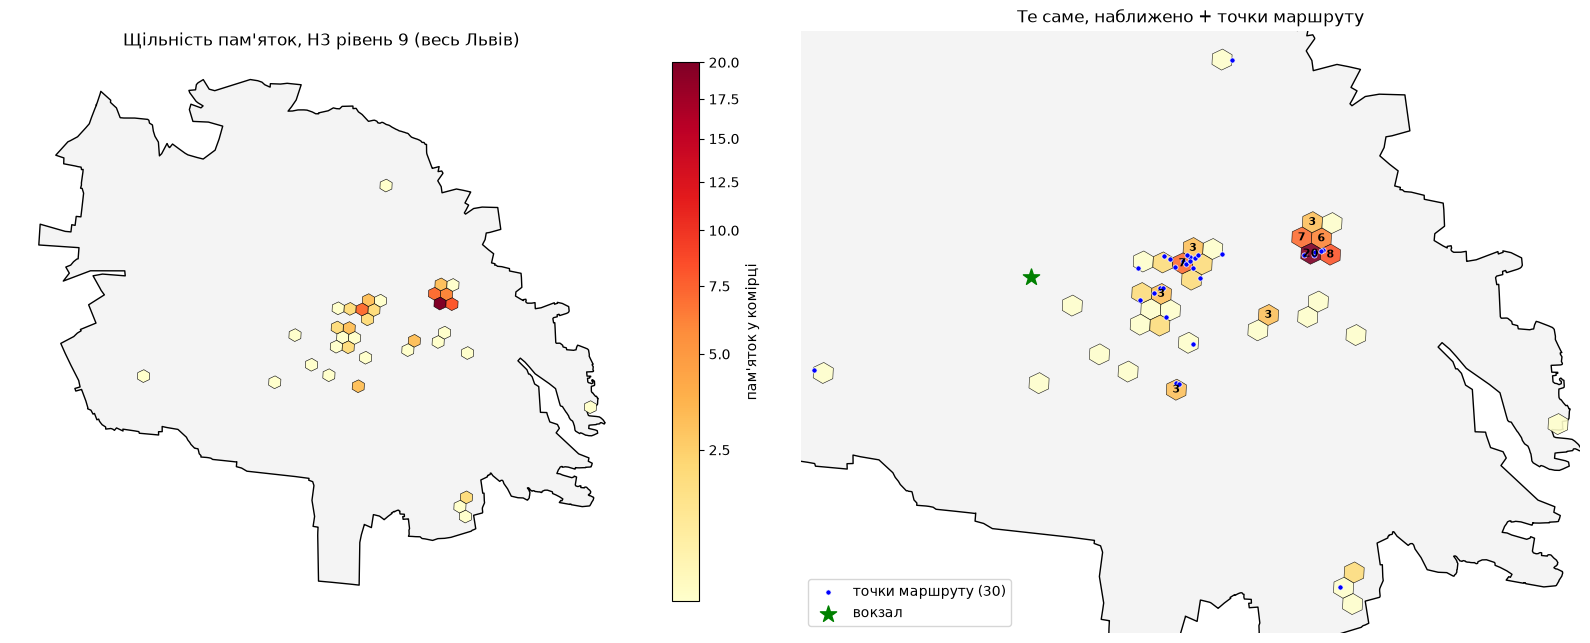

In [177]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

pts = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in pts]

dens = cand.groupby('h3').size().rename('n').reset_index()

def hex_poly(cell):
    return Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(cell)])

hexes = gpd.GeoDataFrame(dens, geometry=[hex_poly(c) for c in dens['h3']], crs='EPSG:4326')

srt = dens['n'].sort_values(ascending=False).values
cum = np.cumsum(srt)
k50 = int(np.searchsorted(cum, 0.5 * cum[-1]) + 1)
print('кандидатів: %d | зайнятих комірок: %d' % (len(cand), len(dens)))
print('половина пам\'яток зосереджена у %d комірках (з %d)' % (k50, len(dens)))
print('максимум в одній комірці:', int(srt[0]))

import matplotlib.colors as mcolors

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

ax = axes[0]
boundary.plot(ax=ax, facecolor='#f4f4f4', edgecolor='black', linewidth=1)
hexes.plot(ax=ax, column='n', cmap='YlOrRd', legend=True, alpha=1.0,
           edgecolor='black', linewidth=0.4,
           norm=mcolors.PowerNorm(gamma=0.5),      
           legend_kwds={'label': "пам'яток у комірці", 'shrink': 0.7})
ax.set_title("Щільність пам'яток, H3 рівень %d (весь Львів)" % H3_RES)
ax.set_axis_off()

ax = axes[1]
minx, miny, maxx, maxy = hexes.total_bounds
pad = 0.003
ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
boundary.plot(ax=ax, facecolor='#f4f4f4', edgecolor='black', linewidth=1)
hexes.plot(ax=ax, column='n', cmap='YlOrRd', alpha=0.9,
           edgecolor='black', linewidth=0.4,
           norm=mcolors.PowerNorm(gamma=0.5))
for _, r in hexes[hexes['n'] >= 3].iterrows():      
    c = r.geometry.centroid
    ax.text(c.x, c.y, int(r['n']), ha='center', va='center', fontsize=8, weight='bold')
pts30.iloc[1:].plot(ax=ax, color='blue', markersize=14, edgecolor='white',
                    linewidth=0.5, label='точки маршруту (30)')
pts30.iloc[[0]].plot(ax=ax, color='green', markersize=150, marker='*', label='вокзал')
ax.set_title('Те саме, наближено + точки маршруту')
ax.legend(loc='lower left')
ax.set_axis_off()

plt.tight_layout()
plt.show()

### Висновок до завдання 7.1 (H3, рівень 9)

95 кандидатів потрапили у 36 комірок H3 рівня 9 (середнє ребро 201 м).
Половина всіх пам'яток зосереджена у 5 комірках із 36, найщільніша
комірка містить 20 об'єктів.

Для маршруту це означає форму щільний клубок + довгі хвости: більшість
точок лежить у кількох сусідніх комірках центру, а решта (західна,
південна, північна й кластер праворуч від центру) розкидані по місту.
Саме віддалені точки, імовірно, дають більшу частину довжини маршруту на
30 точках (52,4 км), бо вокзал і ці точки стоять далеко від центрального
клубка.

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [182]:
pm = pts30.to_crs(32635)
am = amenities.to_crs(32635)
am = am[am['amenity'].notna()]
am = am.assign(am_name=am['name'], am_type=am['amenity'])[['am_name', 'am_type', 'geometry']]

KEEP = ['cafe', 'restaurant', 'drinking_water', 'toilets']
am = amenities.to_crs(32635)
am = am[am['amenity'].isin(KEEP)]
am = am.assign(am_name=am['name'], am_type=am['amenity'])[['am_name', 'am_type', 'geometry']]
print(am['am_type'].value_counts().to_dict())

near = gpd.sjoin_nearest(pm, am, how='left', distance_col='відстань_м')
near = near.drop_duplicates(subset='name')  
display(near[['name', 'am_type', 'am_name', 'відстань_м']]
        .assign(відстань_м=lambda d: d['відстань_м'].round(0))
        .reset_index(drop=True))
print('медіана відстані до найближчого закладу: %.0f м' % near['відстань_м'].median())

{'cafe': 604}


,name,am_type,am_name,відстань_м
0,СТАРТ: Головний вокзал,cafe,Експрес,83.0
1,Національний музей у Львові,cafe,Львівська мануфактура кави,58.0
2,Палац Потоцьких,cafe,ICoffee,93.0
3,Королівський арсенал,cafe,Cold comfort,79.0
4,Львівський музей історії релігії,cafe,Cold comfort,20.0
5,Львівський Державний Природознавчий Музей,cafe,BubbleWaffle,45.0
6,Кам'яниця Корнякта,cafe,Щось Цікаве,27.0
7,"Арсенал, Львівський державний історичний музей...",cafe,Фреска,46.0
8,Будинок вчених,cafe,<NA>,58.0
9,Львівська національна галерея мистецтв,cafe,ICoffee,79.0


медіана відстані до найближчого закладу: 79 м


### Висновок до завдання 8.1

Для кожної з 31 точки (старт + 30 пам'яток) знайдено найближчий заклад
через sjoin_nearest; обидва шари переведено в метричну CRS, бо в градусах відстань безглузда.

Спершу в результат потрапили університети, школи й аптеки: шар
amenities зі знімка Lviv_osm містить ширший набір значень amenity,
ніж у завданні. Я залишила типи cafe, restaurant, drinking_water,
toilets. Після фільтра лишилось 604 об'єкти, і всі вони cafe:
ресторанів, питної води й туалетів у цьому знімку немає. Тож «найближчий
заклад» означає «найближче кафе».

Медіана відстані до найближчого кафе: 79 м. У центрі кафе
знаходиться за 20-96 м від музею. Найвіддаленіші точки: Храм Пресвятої
Трійці (792 м), Каплиця всіх Святих українського народу (633 м),
музеї Франка (468 м) і Грушевського (427 м). 

Для туриста це означає, що центральна частина маршруту добре
забезпечена кав'ярнями, а на периферії пішки до кафе доведеться йти
пів кілометра й більше. Відстані прямі (по прямій), не по вулицях.

---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [179]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

tour = op30  
road = route_coords(tour, ids30)
straight = [(float(pts30.geometry.y.iloc[i]), float(pts30.geometry.x.iloc[i])) for i in tour]

fmap = folium.Map(location=[straight[0][0], straight[0][1]], zoom_start=13,
                  tiles=BASEMAP.build_url(), attr=BASEMAP.html_attribution)

folium.PolyLine(road, color='blue', weight=4, opacity=0.8,
                tooltip='маршрут по ребрах графа').add_to(fmap)
folium.PolyLine(straight, color='red', weight=2, opacity=0.8, dash_array='6',
                tooltip='прямі відрізки між точками').add_to(fmap)

for step, i in enumerate(tour[:-1]):
    lat, lon = float(pts30.geometry.y.iloc[i]), float(pts30.geometry.x.iloc[i])
    folium.Marker([lat, lon],
                  tooltip='%d. %s' % (step, pts30['name'].iloc[i]),
                  icon=folium.DivIcon(html='<div style="background:%s;color:white;'
                      'border-radius:50%%;width:22px;height:22px;text-align:center;'
                      'line-height:22px;font-size:11px">%d</div>'
                      % ('green' if step == 0 else '#1f4fbf', step))).add_to(fmap)

fmap.save('lr5_маршрут.html')

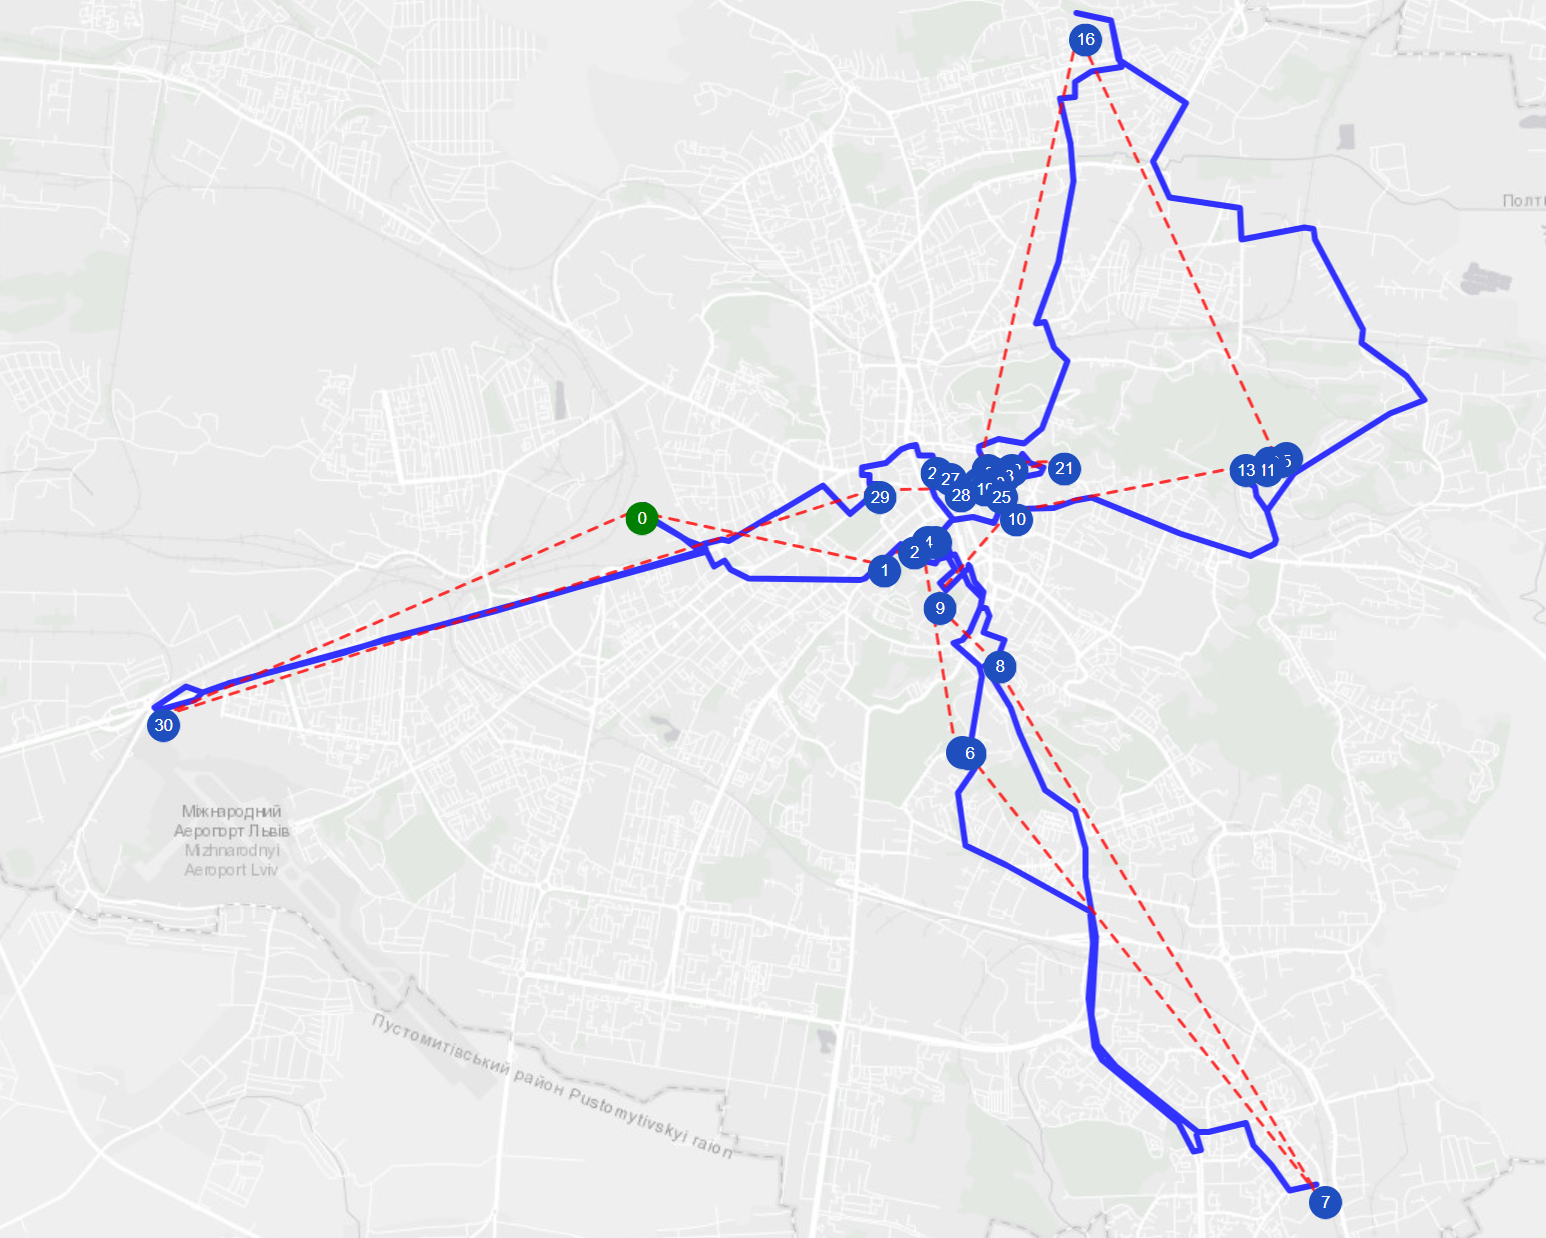

### Висновок до завдання 9.1 (карта маршруту)

На карті lr5_маршрут.html показано два варіанти однієї послідовності
точок (результат 2-opt на 30 пам'ятках): синя суцільна лінія йде по
ребрах графа, червона пунктирна з'єднує точки прямими відрізками.

Маршрут має форму «клубок + хвости»: більшість пам'яток скупчена в
центрі, а кілька віддалених об'єктів (західний, південний, північний і
східний) вимагають довгих виїздів. Найдовший хвіст веде на захід, до
віддаленої точки (номер 30), і проходиться туди й назад майже тією самою
дорогою, тому саме віддалені об'єкти, імовірно, дають більшу частину
довжини 52,4 км. На петлі праворуч і на південному хвості синя лінія
помітно довша за пряму, що узгоджується з коефіцієнтом обходу 1,45.

У центрі кілька маркерів накладаються: це точки, що сіли на спільні
вузли графа. Мережа у знімку автомобільна, тому односторонні вулиці змушують маршрут місцями
повторювати ділянки.

---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [180]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (17.7 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

## Звіт

**Дані.** Через збої Overpass (502, 403, таймаути) дані Черкас (варіант 16)
зібрати не вдалося. Я працювала зі знімком Lviv_osm (Львів). Шари
heritage і stations виділила з шару buildings за тегами.

**1. Що відкинула.** У heritage було 109 об'єктів, за тегами підійшли всі.
Відкинула 14 без name: без назви не можна показати туристу чи
порахувати мови. Без пояснень цей фільтр замовнику не віддала б: серед
відкинутих 4 музеї, historic=yes (18) і house (18) надто загальні, а
всі 95 кандидатів мають геометрію Polygon (пам'ятників-точок немає, бо
buildings їх не містить).

**2. Рейтинг.** score = 0,35·wiki + 0,30·мови + 0,20·тип + 0,15·площа
(мови й площа через rank(pct=True)). Найвагоміший сигнал: стаття
(wikidata/wikipedia), бо це зовнішнє визнання. Далі кількість мов
назви, тип (музей/галерея/атракція) і найслабший сигнал, площа. 

**3. Збіг рейтингів: 7 з 10.** Обидва списки з тих самих даних і того ж
коду, але різні, тож "найкращі" залежить від вибраного критерію. Високий
збіг пояснюється тим, що серед кандидатів великі будівлі це переважно
відомі музеї й палаци. 

**4. Коефіцієнт обходу: 1,83 (10 точок) і 1,45 (30 точок).** Для 10 точок
він вищий за типові 1,2–1,6. Причина: мережа у знімку автомобільна, вузлів мало, а відстань точка - вузол у медіані 71 м (максимум 187 м). Асиметрія матриці 1084 м.

**5. Найближчий сусід гірший за оптимум на 4,05%** (11 126 м проти
10 693 м), 2-opt на 0,95%. На 30 точках 2-opt коротший за найближчого сусіда на 14,5% (52 434 м проти 61 349 м), тож розрив росте з кількістю точок.

**6. Чому точний розв'язок на 30 точках недоступний.** Таблиця Held–Karp
має 2^(n−1)·(n−1) клітин. Для n = 31 це ≈ 32,2 млрд клітин, тобто
≈ 258 ГБ при 8 байтах на клітину. Це значно більше за оперативну пам'ять
комп'ютера: кожна нова точка подвоює таблицю.

**7. Що виявилось неправильним.**
- Знімок не той: Львів замість Черкас, без шарів heritage і stations.
- Мережа автомобільна, а не пішохідна; з 31 точки лише 22 різні вузли
  (9 злиплись), тож у матриці є нульові відстані й довжини занижені.
- Дублікати: один музей під двома назвами, рештки вежі як частина Арсеналу; 
видалила ці 2 об'єкти.
- amenities містить лише кафе (604), тож висновки про воду й туалети
  неможливі.

**Декларація про використання ШІ.** Використовувала Claude для
пояснення теорії та написання коду комірок. Виконувала
кожну комірку, звіряла числа з контрольними ознаками ноутбука, пройшли
assert-самоперевірки. Висновки й рішення про рейтинг та дублікати ухвалювала я.